In [1]:
from langgraph.graph import StateGraph , START , END
from langchain_groq import ChatGroq
from langgraph.checkpoint.memory import MemorySaver
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
import os
llm = ChatGroq(model="openai/gpt-oss-120b",api_key=os.environ.get("GROQ_API_KEY"))

In [3]:
class Joke(TypedDict):
    title : str
    content : str
    expn : str

In [4]:
def genjk(state : Joke):

    prompt = f'generate a joke on the topic {state["title"]}'

    response = llm.invoke(prompt).content

    return {'content' : response}

In [5]:
def expnjk(state : Joke):

    prompt = f'write an explanation for the joke - {state["content"]}'
    response = llm.invoke(prompt).content

    return {'expn' : response}

In [6]:
checkpointer = MemorySaver()

graph = StateGraph(Joke)

graph.add_node('generate_jk',genjk)
graph.add_node('explain_jk',expnjk)

graph.add_edge(START,'generate_jk')
graph.add_edge('generate_jk','explain_jk')
graph.add_edge('explain_jk',END)

wf = graph.compile(checkpointer=checkpointer)


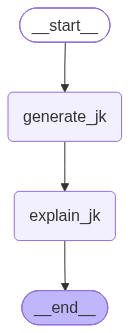

In [7]:
wf

In [12]:

config1 = {"configurable" : {"thread_id" : "1"}}
config2 = {"configurable" : {"thread_id" : "2"}}


In [10]:
wf.invoke({'title' : "Pizza"} , config=config1)

{'title': 'Pizza',
 'content': 'Why did the pizza apply for a job?  \n\nBecause it wanted to earn some **dough** while showing off its **crust**‑worthy work ethic—plus it heard the office has great “slice” time! 🍕😄',
 'expn': '**Explanation of the joke**\n\nThe joke plays on a few pizza‑related words that have double meanings in everyday language. Let’s break down each part:\n\n| Pizza term | Everyday meaning | Why it’s funny in the punchline |\n|------------|------------------|--------------------------------|\n| **Dough**  | 1. The raw mixture of flour, water, yeast, etc., that becomes pizza crust.<br>2. Slang for money (“earning dough”). | Saying the pizza wants to “earn some dough” suggests it’s looking for a paycheck, while also hinting that it literally wants more of the bread‑like base it’s made of. |\n| **Crust‑worthy** | 1. Refers to the pizza’s outer edge, the crust.<br>2. “Worth” or “worthy” is often used to describe something of high quality or reliability. | Describing the

In [18]:
wf.invoke({'title':"Samosa"},config=config2)

{'title': 'Samosa',
 'content': 'Why did the samosa go to therapy?\n\nBecause it was tired of being *filled* with guilt and wanted to *crunch* through its feelings! 😄',
 'expn': '**Joke:**  \n*Why did the samosa go to therapy?*  \n*Because it was tired of being **filled** with guilt and wanted to **crunch** through its emotions!*  \n\n---\n\n### Why it’s funny – the wordplay\n\n| Part of the joke | What it literally means (food‑related) | What it figuratively means (psychology/feelings) |\n|------------------|----------------------------------------|---------------------------------------------------|\n| **“filled”** | A samosa is a pastry that’s stuffed with a savory filling (potatoes, peas, meat, etc.). | “Filled with guilt” is a common expression for feeling weighed down by remorse. |\n| **“crunch”** | When you bite a samosa you hear a satisfying *crunch* because the pastry is crispy. | To “crunch through” something suggests tackling a problem head‑on, breaking it down, or processin

In [20]:
wf.get_state(config=config1)

StateSnapshot(values={'title': 'Pizza', 'content': 'Why did the pizza apply for a job?  \n\nBecause it wanted to earn some **dough** while showing off its **crust**‑worthy work ethic—plus it heard the office has great “slice” time! 🍕😄', 'expn': '**Explanation of the joke**\n\nThe joke plays on a few pizza‑related words that have double meanings in everyday language. Let’s break down each part:\n\n| Pizza term | Everyday meaning | Why it’s funny in the punchline |\n|------------|------------------|--------------------------------|\n| **Dough**  | 1. The raw mixture of flour, water, yeast, etc., that becomes pizza crust.<br>2. Slang for money (“earning dough”). | Saying the pizza wants to “earn some dough” suggests it’s looking for a paycheck, while also hinting that it literally wants more of the bread‑like base it’s made of. |\n| **Crust‑worthy** | 1. Refers to the pizza’s outer edge, the crust.<br>2. “Worth” or “worthy” is often used to describe something of high quality or reliabilit

In [21]:
wf.get_state(config=config2)

StateSnapshot(values={'title': 'Samosa', 'content': 'Why did the samosa go to therapy?\n\nBecause it was tired of being *filled* with guilt and wanted to *crunch* through its feelings! 😄', 'expn': '**Joke:**  \n*Why did the samosa go to therapy?*  \n*Because it was tired of being **filled** with guilt and wanted to **crunch** through its emotions!*  \n\n---\n\n### Why it’s funny – the wordplay\n\n| Part of the joke | What it literally means (food‑related) | What it figuratively means (psychology/feelings) |\n|------------------|----------------------------------------|---------------------------------------------------|\n| **“filled”** | A samosa is a pastry that’s stuffed with a savory filling (potatoes, peas, meat, etc.). | “Filled with guilt” is a common expression for feeling weighed down by remorse. |\n| **“crunch”** | When you bite a samosa you hear a satisfying *crunch* because the pastry is crispy. | To “crunch through” something suggests tackling a problem head‑on, breaking it

In [ ]:
list(wf.get_state_history(config=config1))

[StateSnapshot(values={'title': 'Pizza', 'content': 'Why did the pizza apply for a job?  \n\nBecause it wanted to earn some **dough** while showing off its **crust**‑worthy work ethic—plus it heard the office has great “slice” time! 🍕😄', 'expn': '**Explanation of the joke**\n\nThe joke plays on a few pizza‑related words that have double meanings in everyday language. Let’s break down each part:\n\n| Pizza term | Everyday meaning | Why it’s funny in the punchline |\n|------------|------------------|--------------------------------|\n| **Dough**  | 1. The raw mixture of flour, water, yeast, etc., that becomes pizza crust.<br>2. Slang for money (“earning dough”). | Saying the pizza wants to “earn some dough” suggests it’s looking for a paycheck, while also hinting that it literally wants more of the bread‑like base it’s made of. |\n| **Crust‑worthy** | 1. Refers to the pizza’s outer edge, the crust.<br>2. “Worth” or “worthy” is often used to describe something of high quality or reliabili

In [24]:
list(wf.get_state_history(config=config2))

[StateSnapshot(values={'title': 'Samosa', 'content': 'Why did the samosa go to therapy?\n\nBecause it was tired of being *filled* with guilt and wanted to *crunch* through its feelings! 😄', 'expn': '**Joke:**  \n*Why did the samosa go to therapy?*  \n*Because it was tired of being **filled** with guilt and wanted to **crunch** through its emotions!*  \n\n---\n\n### Why it’s funny – the wordplay\n\n| Part of the joke | What it literally means (food‑related) | What it figuratively means (psychology/feelings) |\n|------------------|----------------------------------------|---------------------------------------------------|\n| **“filled”** | A samosa is a pastry that’s stuffed with a savory filling (potatoes, peas, meat, etc.). | “Filled with guilt” is a common expression for feeling weighed down by remorse. |\n| **“crunch”** | When you bite a samosa you hear a satisfying *crunch* because the pastry is crispy. | To “crunch through” something suggests tackling a problem head‑on, breaking i

In [26]:
wf.get_state({"configurable":{"thread_id" : "2",'checkpoint_id': '1f1d286e-c955-624f-8003-7666d00ac3fd'}})

StateSnapshot(values={'title': 'Pasta', 'content': 'Why did the spaghetti go to therapy?\n\nBecause it couldn’t *knot* handle all the twists and turns in its life! 🍝😆', 'expn': '**Joke:**  \n*Why did the spaghetti go to therapy?*  \n*Because it couldn’t **knot** handle all the twists and turns in its life!* 🍝😆  \n\n---\n\n### Why it’s funny\n\n| Element | What it means | Why it’s a punchline |\n|---------|---------------|----------------------|\n| **Spaghetti** | A long, thin pasta that’s naturally *twisty* and often ends up in a tangled heap on a plate. | The image of a noodle having a “life” is already absurd, setting the stage for a silly punchline. |\n| **Therapy** | A place where people (or, in a joke, anything) go to work through emotional or psychological problems. | Giving a food item a human‑like need for therapy heightens the silliness. |\n| **“knot” vs. “not”** | The word *knot* (a literal loop or tangle) sounds exactly like *not* (the negative). The joke swaps the usual “co